# VibeWorld — Exploration du Dataset Moving MNIST

Ce notebook explore le dataset Moving MNIST à l'aide de la classe `MovingMNISTDataset` implémentée dans `src/dataset.py`.

In [1]:
import sys
import os

# Ajouter le dossier src au path pour importer le dataset
sys.path.append(os.path.abspath('../'))

import numpy as np
import torch
import matplotlib.pyplot as plt
from src.dataset import MovingMNISTDataset

## 1. Chargement des Datasets (Train / Val)

Nous chargeons les splits d'entraînement et de validation.

In [2]:
filepath = '../data/raw/mnist_test_seq.npy'

train_dataset = MovingMNISTDataset(filepath, split='train')
val_dataset = MovingMNISTDataset(filepath, split='val')

print(f"Taille du dataset d'entraînement : {len(train_dataset)}")
print(f"Taille du dataset de validation : {len(val_dataset)}")

Taille du dataset d'entraînement : 8000
Taille du dataset de validation : 2000


## 2. Statistiques basiques

Analysons la forme des tenseurs retournés et les statistiques des pixels (min, max, moyenne).

In [3]:
# Récupérer le premier élément
inputs, targets = train_dataset[0]

print(f"Shape des frames d'entrée : {inputs.shape}")
print(f"Shape des frames cibles  : {targets.shape}")

# Statistiques
all_frames = torch.cat([inputs, targets], dim=0)
print(f"Valeur minimale des pixels : {all_frames.min().item():.4f}")
print(f"Valeur maximale des pixels : {all_frames.max().item():.4f}")
print(f"Valeur moyenne des pixels  : {all_frames.mean().item():.4f}")

Shape des frames d'entrée : torch.Size([10, 1, 64, 64])
Shape des frames cibles  : torch.Size([10, 1, 64, 64])
Valeur minimale des pixels : 0.0000
Valeur maximale des pixels : 1.0000
Valeur moyenne des pixels  : 0.0518


## 3. Visualisation de séquences complètes

Nous allons afficher 3 séquences aléatoires sous forme d'une grille. Chaque ligne correspond à une séquence complète de 20 frames (les 10 premières frames d'entrée et les 10 frames cibles suivantes) côte à côte.

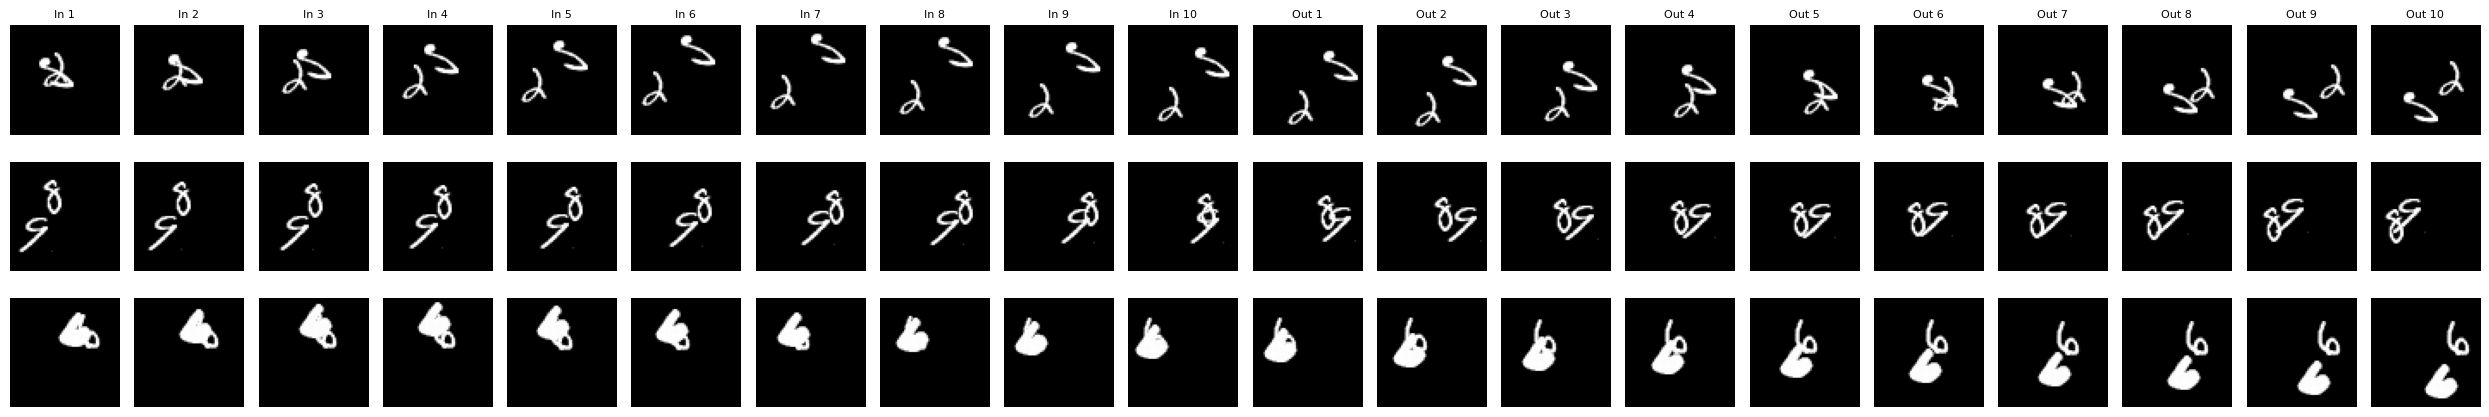

In [4]:
np.random.seed(42)
indices = np.random.choice(len(train_dataset), size=3, replace=False)

fig, axes = plt.subplots(3, 20, figsize=(25, 4.5))

for i, idx in enumerate(indices):
    inputs, targets = train_dataset[idx]
    # Fusionner les entrées et les cibles pour obtenir les 20 frames de la séquence
    full_seq = torch.cat([inputs, targets], dim=0) # shape (20, 1, 64, 64)
    
    for f in range(20):
        ax = axes[i, f]
        # Retirer le canal pour l'affichage (grayscale)
        img = full_seq[f, 0].numpy()
        ax.imshow(img, cmap='gray')
        ax.axis('off')
        
        # Labéliser les frames pour plus de clarté
        if i == 0:
            if f < 10:
                ax.set_title(f"In {f+1}", fontsize=8)
            else:
                ax.set_title(f"Out {f-9}", fontsize=8)
                
plt.tight_layout()
plt.show()